In [1]:
!pip install gym_bandits

In [3]:
import gym
import gym_bandits
import numpy as np

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [5]:
env=gym.make("MultiarmedBandits-v0")

/usr/local/lib/python3.12/dist-packages/gym/core.py:317: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/usr/local/lib/python3.12/dist-packages/gym/wrappers/step_api_compatibility.py:39: DeprecationWarning: WARN: Initializing environment in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(


In [8]:
print(env.observation_space)

Discrete(1)


In [9]:
print(env.action_space)

Discrete(10)


In [13]:
n_arms=env.action_space.n
nums_episodes=500
epsilon=0.1
q_values=np.zeros(n_arms)
counts=np.zeros(n_arms)
reward_sum=np.zeros(n_arms)
all_rewards=[]
action_history=[]
for episode in range(nums_episodes):
  env.reset()
  if np.random.rand()<epsilon:
    action=env.action_space.sample()
  else:
    action=np.argmax(q_values)
  observation, reward, done, info = env.step(action)
  counts[action]+=1
  reward_sum[action]
  q_values[action]=reward_sum[action]/counts[action]
  all_rewards.append(reward)
  action_history.append(action)
env.close()
print("Estimated Q-values for each arm:",np.round(q_values,2))
print("Number of times each arm was selected",counts.astype(int))
print("Average reward over all episodes:",round(np.mean(all_rewards),3))


Estimated Q-values for each arm: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Number of times each arm was selected [456   8   5   4   8   0   4   2   6   7]
Average reward over all episodes: 0.034


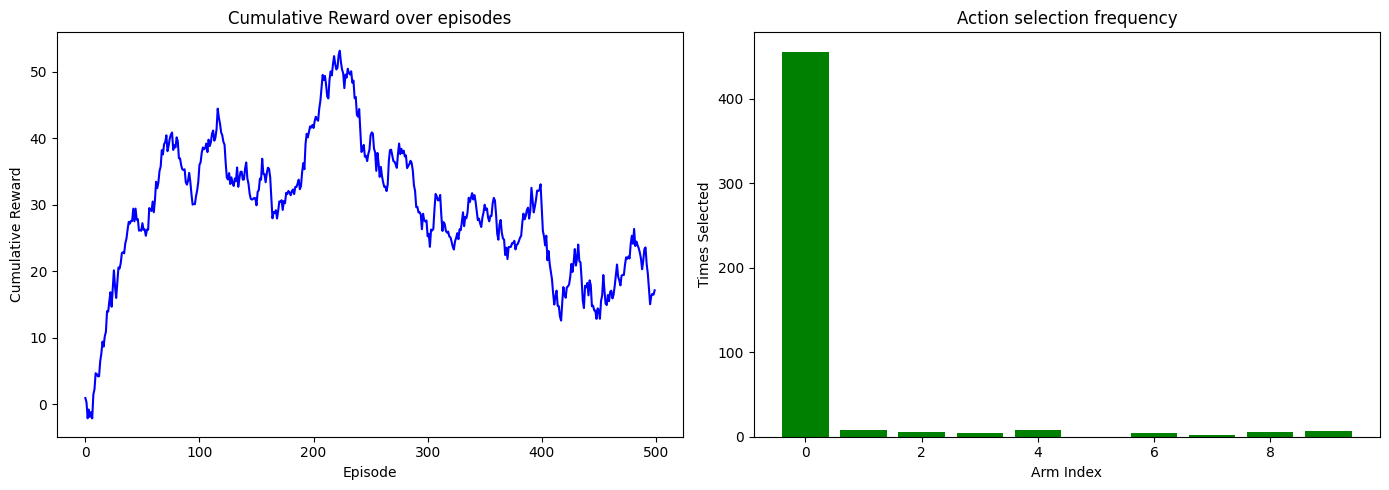

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,5))
plt.subplot(1,2,1)
plt.plot(np.cumsum(all_rewards),color='blue')
plt.title("Cumulative Reward over episodes")
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")
plt.subplot(1,2,2)
plt.bar(np.arange(n_arms),counts,color='green')
plt.title("Action selection frequency")
plt.xlabel("Arm Index")
plt.ylabel("Times Selected")
plt.tight_layout()
plt.show()